# Parte 3 — Dónde y por qué falla el modelo

**Objetivo:** las métricas globales esconden patrones de error que importan para la
validación y para el negocio. Esta notebook busca:

- el perfil de los **falsos negativos** más costosos (aprobados con PD baja que entran en default);
- el perfil de los **falsos positivos** más claros (rechazados con PD alta que hubieran pagado);
- los segmentos donde el modelo discrimina peor;
- las limitaciones para el Model Card.

Se usa la PD calibrada y la regla de decisión de la política: rechazar si PD ≥ PD\* del
mercado de referencia (ver notebook 02).

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

from src.config import load_policy, reference_cutoff
from src.models.pd_model import PDScorer
from src.validation.model_validation import age_groups

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

policy = load_policy()
ref    = policy['mercados'][policy['mercado_referencia']]
CUTOFF, LGD, TASA = reference_cutoff(policy), ref['lgd'], ref['tasa_interes_anual']

scorer   = PDScorer()
X_test   = pd.read_parquet('data/processed/X_test.parquet')
y_test   = pd.read_parquet('data/processed/y_test.parquet').iloc[:, 0].values
raw_test = pd.read_parquet('data/processed/test.parquet')
pd_test  = scorer.pd_from_features(X_test)

a = raw_test.copy()
a['pd']   = pd_test
a['real'] = y_test
a['rechazado'] = (a['pd'] >= CUTOFF).astype(int)
a['tipo'] = 'correcto'
a.loc[(a['real'] == 1) & (a['rechazado'] == 0), 'tipo'] = 'falso_negativo'
a.loc[(a['real'] == 0) & (a['rechazado'] == 1), 'tipo'] = 'falso_positivo'
a['age_group'] = age_groups(a['age_years']).values

print(f'Cutoff PD: {CUTOFF:.1%} (break-even {policy["mercado_referencia"]}) | LGD {LGD:.0%} | tasa {TASA:.1%}')
print(a['tipo'].value_counts())

Cutoff PD: 20.3% (break-even USA) | LGD 45% | tasa 11.5%
tipo
correcto          54783
falso_negativo     3571
falso_positivo     3149
Name: count, dtype: int64


## 3.1 Ordenamiento y calibración por decil

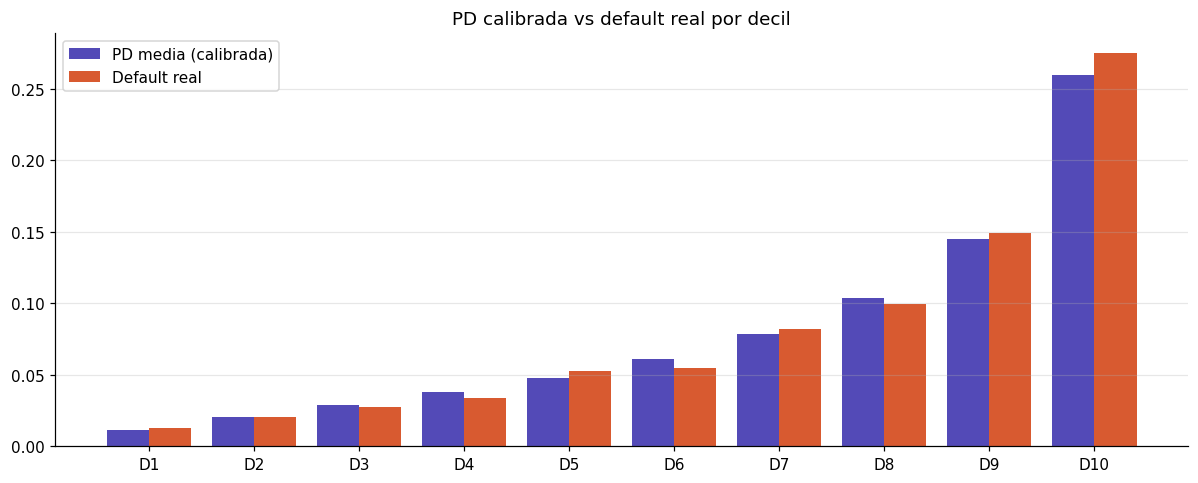

,n,pd_media,default_real,defaults,rechazo,captura_acum_desde_D10
decil,,,,,,
D1,6151,0.0115,0.0127,78,0.0000,1.0000
D2,6150,0.0208,0.0203,125,0.0000,0.9843
D3,6150,0.0289,0.0276,170,0.0000,0.9591
D4,6150,0.0378,0.0337,207,0.0000,0.9249
D5,6151,0.0480,0.0525,323,0.0000,0.8832
D6,6150,0.0609,0.0546,336,0.0000,0.8181
D7,6150,0.0784,0.0823,506,0.0000,0.7505
D8,6150,0.1035,0.0993,611,0.0000,0.6485
D9,6150,0.1449,0.1491,917,0.0000,0.5255


In [2]:
a['decil'] = pd.qcut(a['pd'].rank(method='first'), 10, labels=[f'D{i}' for i in range(1, 11)])
dec = a.groupby('decil', observed=True).agg(
    n=('pd', 'size'), pd_media=('pd', 'mean'), default_real=('real', 'mean'),
    defaults=('real', 'sum'), rechazo=('rechazado', 'mean'))
dec['captura_acum_desde_D10'] = dec['defaults'][::-1].cumsum()[::-1] / dec['defaults'].sum()

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(10)
ax.bar(x - 0.2, dec['pd_media'], 0.4, color='#534AB7', label='PD media (calibrada)')
ax.bar(x + 0.2, dec['default_real'], 0.4, color='#D85A30', label='Default real')
ax.set_xticks(x); ax.set_xticklabels(dec.index)
ax.set_title('PD calibrada vs default real por decil'); ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.savefig('reports/figures/error_por_decil.png', dpi=150, bbox_inches='tight'); plt.show()
dec.round(4)

## 3.2 Falsos negativos de alta confianza

Son clientes que el modelo aprueba con PD en el quintil más bajo y que igual entran en
default. Es la pérdida más difícil de anticipar.

In [3]:
q20 = np.quantile(a['pd'], 0.20)
fn = a[(a['real'] == 1) & (a['pd'] <= q20)]
total_fn = (a['tipo'] == 'falso_negativo').sum()
print(f'Falsos negativos totales con el cutoff: {total_fn:,}')
print(f'FN de alta confianza (PD <= {q20:.2%}, quintil inferior): {len(fn):,}')
print(f'Pérdida estimada de esos FN (EAD x LGD): {(fn["AMT_CREDIT"] * LGD).sum():,.0f}')
print()
perfil = pd.DataFrame({
    'FN alta confianza': [fn['age_years'].mean(), -fn['DAYS_EMPLOYED'].mean() / 365,
                          fn['EXT_SOURCE_2'].mean(), fn['EXT_SOURCE_3'].mean(),
                          fn['annuity_income_ratio'].mean(), (fn['CODE_GENDER'] == 'F').mean()],
    'Cartera total':     [a['age_years'].mean(), -a['DAYS_EMPLOYED'].mean() / 365,
                          a['EXT_SOURCE_2'].mean(), a['EXT_SOURCE_3'].mean(),
                          a['annuity_income_ratio'].mean(), (a['CODE_GENDER'] == 'F').mean()],
}, index=['edad media', 'años de empleo', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'cuota / ingreso', '% mujeres'])
display(perfil.round(3))
print('Tipo de ingreso en FN de alta confianza:')
print(fn['NAME_INCOME_TYPE'].value_counts(normalize=True).head(5).round(3).to_string())

Falsos negativos totales con el cutoff: 3,571
FN de alta confianza (PD <= 2.48%, quintil inferior): 203
Pérdida estimada de esos FN (EAD x LGD): 53,450,606



,FN alta confianza,Cartera total
edad media,47.667,44.019
años de empleo,10.424,6.523
EXT_SOURCE_2,0.631,0.515
EXT_SOURCE_3,0.650,0.511
cuota / ingreso,0.170,0.181
% mujeres,0.749,0.659


Tipo de ingreso en FN de alta confianza:
NAME_INCOME_TYPE
Working                 0.419
Commercial associate    0.256
Pensioner               0.227
State servant           0.099


### Perfil de los falsos negativos

Hay 203 defaults entre los clientes con PD en el quintil más bajo (≤ 2,5%). Frente a la
cartera, tienen:

| | FN alta confianza | Cartera |
|---|---:|---:|
| Antigüedad laboral | 10,4 años | 6,5 años |
| EXT_SOURCE_2 | 0,63 | 0,52 |
| EXT_SOURCE_3 | 0,65 | 0,51 |
| Edad | 47,7 años | 44,0 años |
| % mujeres | 75% | 66% |

La carga de la cuota sobre el ingreso es similar a la de la cartera (0,17 vs 0,18).

**Hipótesis.** Son clientes con todas las señales "buenas" que el modelo puede ver: buen
bureau y empleo estable. Si entran en default, probablemente es por eventos que no están en
`application_train` (pérdida de empleo posterior, salud, endeudamiento en otras entidades).
Esa información estaría en `bureau.csv` y `previous_application.csv`, que este proyecto no usa.

**Recomendación.** No es un error que se corrija con una regla; es un límite de la
información disponible. El paso concreto es incorporar variables de comportamiento de bureau
(saldos y atrasos recientes). La pérdida estimada de este grupo es de ~53 M en unidades
monetarias del dataset (EAD × LGD).

## 3.3 Falsos positivos de alta confianza

Son clientes rechazados con PD en el 5% más alto que igual hubieran pagado. Representan
ingreso perdido y son un posible canal de impacto diferencial.

In [4]:
q95 = np.quantile(a['pd'], 0.95)
fp = a[(a['tipo'] == 'falso_positivo') & (a['pd'] >= q95)]
total_fp = (a['tipo'] == 'falso_positivo').sum()
print(f'Falsos positivos totales con el cutoff: {total_fp:,}')
print(f'FP de alta confianza (PD >= {q95:.2%}): {len(fp):,}')
print(f'Ingreso por intereses resignado en esos FP (EAD x tasa): {(fp["AMT_CREDIT"] * TASA).sum():,.0f}')
comp = pd.DataFrame({
    'FP': fp['CODE_GENDER'].value_counts(normalize=True),
    'Cartera': a['CODE_GENDER'].value_counts(normalize=True),
}).loc[['F', 'M']]
comp['ratio FP/cartera'] = comp['FP'] / comp['Cartera']
display(comp.round(3))
comp_age = pd.DataFrame({
    'FP': fp['age_group'].value_counts(normalize=True),
    'Cartera': a['age_group'].value_counts(normalize=True),
}).reindex(['<25', '25-35', '35-45', '45-55', '>55'])
comp_age['ratio FP/cartera'] = comp_age['FP'] / comp_age['Cartera']
display(comp_age.round(3))

Falsos positivos totales con el cutoff: 3,149
FP de alta confianza (PD >= 23.62%): 2,031
Ingreso por intereses resignado en esos FP (EAD x tasa): 114,420,443


,FP,Cartera,ratio FP/cartera
CODE_GENDER,,,
F,0.535,0.659,0.812
M,0.465,0.340,1.365


,FP,Cartera,ratio FP/cartera
age_group,,,
<25,0.089,0.039,2.263
25-35,0.424,0.234,1.814
35-45,0.298,0.274,1.090
45-55,0.152,0.229,0.664
>55,0.036,0.224,0.162


In [5]:
# ¿Qué features empujan a esos rechazos? SHAP medio en los FP de alta confianza
import pickle
with open('models/champion/shap_explainer.pkl', 'rb') as f:
    explainer = pickle.load(f)
sample = fp.sample(min(300, len(fp)), random_state=42)
sv = explainer.shap_values(X_test.loc[sample.index])
imp = pd.Series(sv.mean(axis=0), index=[c.replace('num__', '').replace('cat__', '') for c in X_test.columns])
print('Features con mayor contribución media al riesgo en FP de alta confianza (log-odds):')
print(imp.sort_values(ascending=False).head(8).round(3).to_string())

Features con mayor contribución media al riesgo en FP de alta confianza (log-odds):
EXT_SOURCE_3          0.597
EXT_SOURCE_2          0.524
AMT_GOODS_PRICE       0.114
EXT_SOURCE_1          0.111
credit_goods_ratio    0.088
DAYS_EMPLOYED         0.082
AMT_ANNUITY           0.051
age_years             0.037


### Falsos positivos y fairness

**Sobre-representación en rechazos incorrectos.** Entre los 2.031 FP de alta confianza
(PD ≥ 23,6%):
- **Hombres:** son el 34% de la cartera pero el 46,5% de estos FP (ratio 1,37).
- **Edad:** es lo más marcado. Los menores de 25 tienen un ratio de 2,26 y los de 25–35, de
  1,81; los mayores de 55, de 0,16.

**Qué empuja esos rechazos (SHAP medio).** Casi todo viene de EXT_SOURCE_3 (+0,60 log-odds)
y EXT_SOURCE_2 (+0,52). Después aparecen AMT_GOODS_PRICE, EXT_SOURCE_1 y el ratio
crédito/bien. La edad directa aporta poco (+0,04).

**Lectura.** El sesgo por edad en los rechazos no viene principalmente de la variable edad,
sino de los scores de bureau, que son más bajos en jóvenes. Además, EXT_SOURCE_1 tiene una correlación de 0,60 con la edad (notebook 01 §1.4), así que el score externo ya incorpora la edad.
Es un caso típico de *proxy*: sacar `age_years` del modelo reduciría poco la brecha. La
mitigación real pasa por:
- revisión manual de jóvenes rechazados cerca del cutoff;
- fuentes de datos alternativas para *thin files* (clientes con poco historial).

**¿Es discriminación?** Es impacto diferencial medible, y hay que documentarlo. Que sea
legalmente aceptable depende de si existe una justificación de negocio y una alternativa
menos discriminatoria (ECOA / Reg B). Esa evaluación es legal, no estadística.

**Costo de oportunidad.** El interés resignado en estos FP es de ~114 M en unidades
monetarias del dataset (EAD × tasa de USA).

## 3.4 Performance por segmento

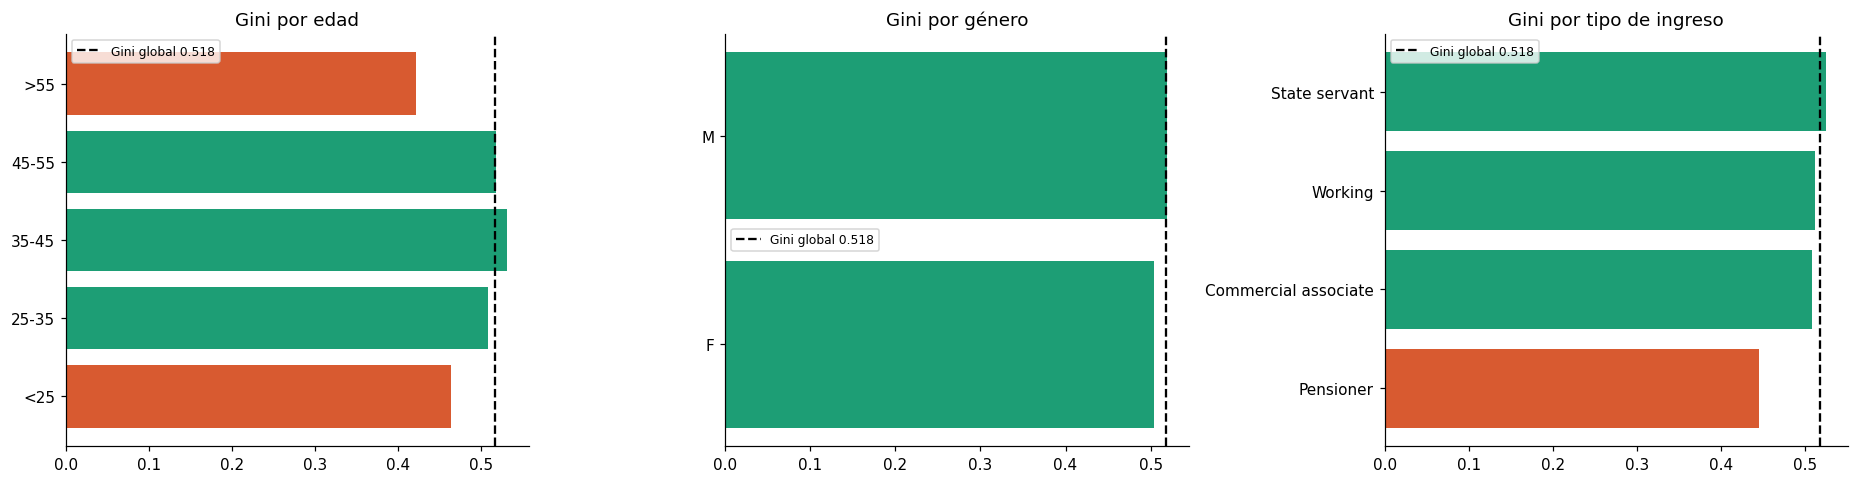

gini
dimensión       segmento                    
Edad            <25                   0.4636
                25-35                 0.5090
                35-45                 0.5317
                45-55                 0.5180
                >55                   0.4217
Género          F                     0.5035
                M                     0.5187
Tipo de ingreso Pensioner             0.4451
                Commercial associate  0.5090
                Working               0.5117
                State servant         0.5251

In [6]:
def gini_seg(df):
    if len(df) < 500 or df['real'].nunique() < 2:
        return np.nan
    return 2 * roc_auc_score(df['real'], df['pd']) - 1

gini_global = gini_seg(a)
segs = {
    'Edad': a.groupby('age_group')[['real', 'pd']].apply(gini_seg).reindex(['<25', '25-35', '35-45', '45-55', '>55']),
    'Género': a[a['CODE_GENDER'].isin(['M', 'F'])].groupby('CODE_GENDER')[['real', 'pd']].apply(gini_seg),
    'Tipo de ingreso': a.groupby('NAME_INCOME_TYPE')[['real', 'pd']].apply(gini_seg).dropna().sort_values(),
}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (nombre, s) in zip(axes, segs.items()):
    s = s.dropna()
    ax.barh(s.index.astype(str), s.values,
            color=['#D85A30' if v < gini_global - 0.05 else '#1D9E75' for v in s.values])
    ax.axvline(gini_global, color='black', ls='--', label=f'Gini global {gini_global:.3f}')
    ax.set_title(f'Gini por {nombre.lower()}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('reports/figures/gini_por_segmento.png', dpi=150, bbox_inches='tight'); plt.show()
pd.concat(segs, names=['dimensión', 'segmento']).round(4).to_frame('gini')

### Segmentos problemáticos

**Los segmentos más débiles son los mayores de 55 (Gini 0,422) y los pensionados (0,445).**
Están unos 10 puntos por debajo del Gini global (0,518), y son en gran parte la misma
población. Los menores de 25 (0,464) también quedan debajo.

**Hipótesis.**
- **Variables que pierden sentido:** la antigüedad laboral es una de las features más
  informativas, y en un pensionado no significa nada.
- **Pocos eventos:** la tasa de default de >55 es 5,4%, así que el segmento tiene menos
  defaults con los que separar.

**Por qué importa aunque el riesgo sea bajo.** Que el Gini sea bajo no quiere decir que el
segmento sea riesgoso: quiere decir que el modelo ordena peor *dentro* del segmento. Como
la PD de >55 es baja, casi no se los rechaza (aprobación 98,6%). El problema, entonces, es
la calidad del ordenamiento para pricing, más que los rechazos.

## 3.5 Limitaciones conocidas (para el Model Card)

1. **Discriminación menor en >55 y pensionados** (Gini 0,42–0,45 vs 0,52). Mitigación:
   monitorear el Gini del segmento por separado; si se usa la PD para pricing, considerar un
   modelo específico para el segmento.
2. **Falsos negativos con buen bureau** (203 defaults en el quintil de menor PD). Son una
   limitación de la información disponible. Mitigación: sumar `bureau` y `previous_application`.
3. **Impacto diferencial por edad en los rechazos**, transmitido sobre todo por los scores de
   bureau. Mitigación: revisión manual de jóvenes rechazados cerca del cutoff y documentar la
   justificación de negocio.
4. **Sin dimensión temporal.** No hay validación out-of-time; la estabilidad en el tiempo no
   está probada.
5. **Alcance:** ingresos "Unemployed", "Student" y "Maternity leave" tienen muy pocos casos
   (menos de 500 en el test) y no se validaron por separado.